In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from xgboost import XGBRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.multioutput import MultiOutputRegressor
from sklearn.linear_model import ElasticNet

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


df= pd.read_csv("./dataset/cleaned_dataset_v2.3.csv")

COLUMN = df.columns
FEATURE_COLUMN = COLUMN[2:17]
DAYS_COLUMN = COLUMN[16:]

In [2]:
# Feature engineering
df=df.drop(columns=['S'],axis=1)
df['Sand/Water']=df['Sand']/df['Water']

# Fetature selection
new_df=df.drop(columns=['Sand','Water','print_type_Cast','Nano-Silica','Fly_ash','Ultrafine_Fly_ash','Ordinary_Portland_Cement'],axis=1)

new_df.info()

target_cols = [f"day_{i:02d}" for i in range(1, 31)]

X = new_df.drop(columns=target_cols[1:] + ["Mix_name"])
y = new_df[target_cols]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17 entries, 0 to 16
Data columns (total 39 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Mix_name            17 non-null     object 
 1   print_type_Printed  17 non-null     bool   
 2   Binder_Weight       17 non-null     float64
 3   SP                  17 non-null     float64
 4   VMA                 17 non-null     float64
 5   Glass_fiber         17 non-null     float64
 6   PP_fiber            17 non-null     float64
 7   Mix_Weight          17 non-null     float64
 8   day_01              17 non-null     float64
 9   day_02              17 non-null     float64
 10  day_03              17 non-null     float64
 11  day_04              17 non-null     float64
 12  day_05              17 non-null     float64
 13  day_06              17 non-null     float64
 14  day_07              17 non-null     float64
 15  day_08              17 non-null     float64
 16  day_09    

## MODEL - 1

In [3]:
# model-1
base_model = XGBRegressor(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:absoluteerror",
    random_state=42
)
model = MultiOutputRegressor(base_model)

model.fit(X, y)

# make the predictions monotonic
y_pred = model.predict(X)
n_outputs = y_pred.shape[1]
x_iso = np.arange(n_outputs)

y_pred_mono = np.vstack([
    IsotonicRegression(increasing=False).fit_transform(x_iso, row)
    for row in y_pred
])

In [4]:
mae_raw = mean_absolute_error(y.values.flatten(), y_pred.flatten())
mse_raw = mean_squared_error(y.values.flatten(), y_pred.flatten())
r2_raw = r2_score(y.values.flatten(), y_pred.flatten())

mae_mono = mean_absolute_error(y.values.flatten(), y_pred_mono.flatten())
mse_mono = mean_squared_error(y.values.flatten(), y_pred_mono.flatten())
r2_mono = r2_score(y.values.flatten(), y_pred_mono.flatten())

print("Raw MAE:", mae_raw)
print("Raw MSE:",mse_raw)
print("Raw R2:",r2_raw)


print("\nMonotonic MAE:", mae_mono)
print("Monotonic MSE:", mse_mono)
print("Monotonic R2:", r2_mono)

Raw MAE: 0.008619678175683137
Raw MSE: 0.00022508420507126974
Raw R2: 0.9996612177477477

Monotonic MAE: 0.008576128439809805
Monotonic MSE: 0.00020224120657363093
Monotonic R2: 0.9996955995582207


In [5]:
y_pred=pd.DataFrame(y_pred_mono)

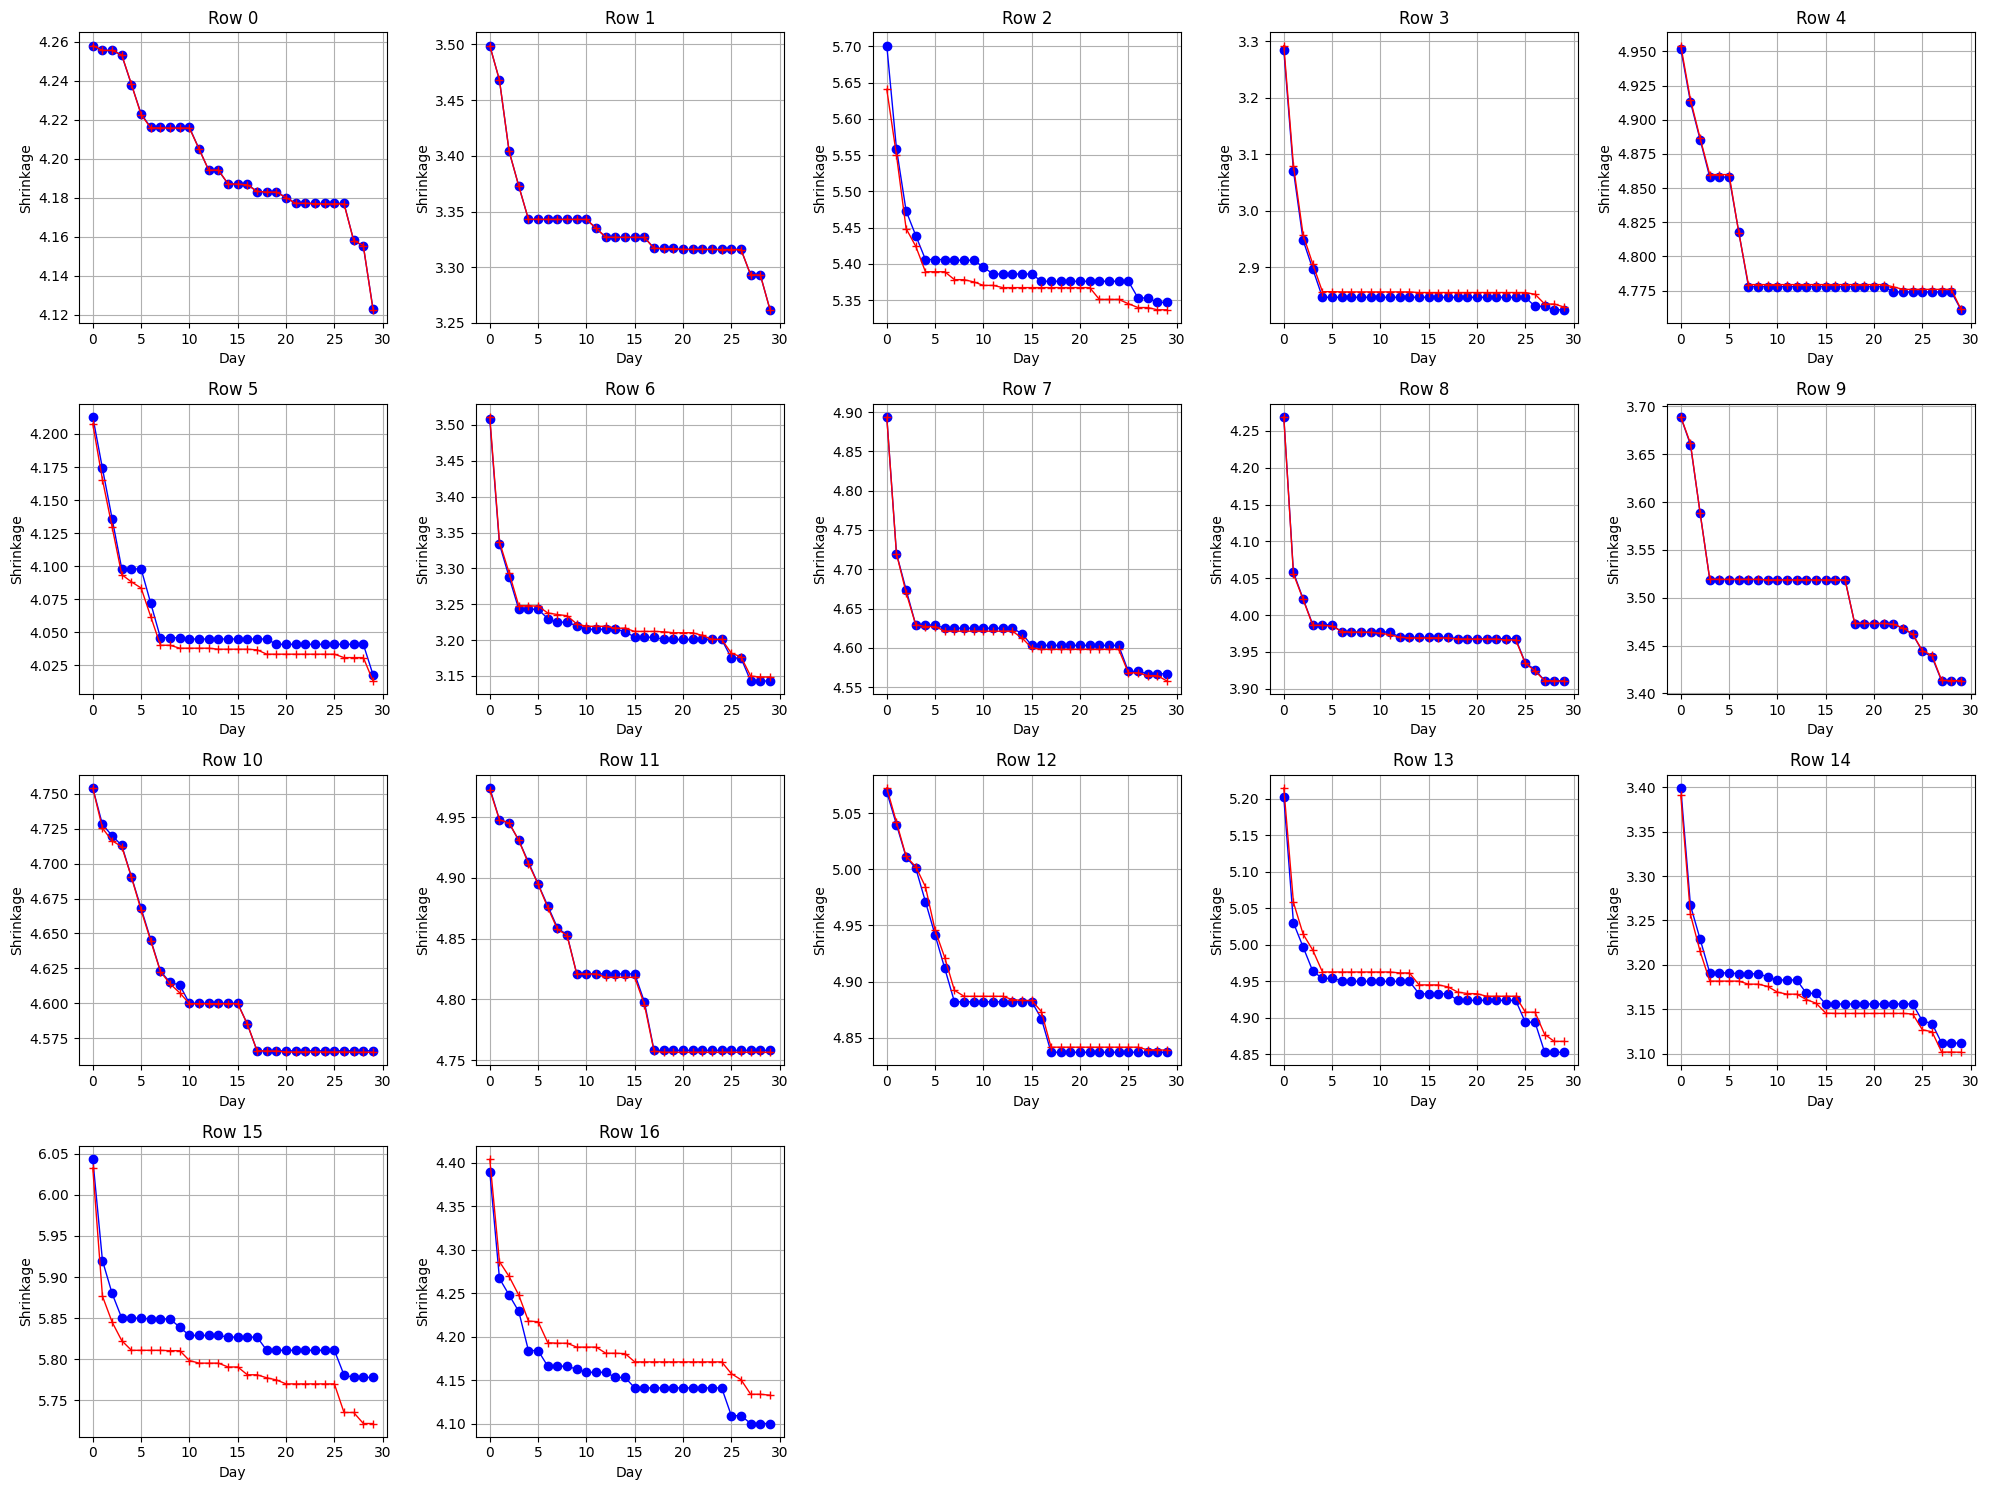

In [6]:
num_rows = y.shape[0]           
cols = 5
rows = math.ceil(num_rows / cols)
    
plt.figure(figsize=(20, 15))
    
for i in range(0,num_rows):
    plt.subplot(rows, cols, i + 1)
   # Plot the actual data in blue with circles
    plt.plot(y.iloc[i].values, marker='o', linewidth=1, color='blue', label='Actual')
    plt.plot(y_pred.iloc[i].values, marker='+', linewidth=1, color='red', label='Predicted')
    plt.title(f"Row {i}")
    plt.xlabel("Day")
    plt.ylabel("Shrinkage")
    plt.grid(True)
    
plt.tight_layout()
plt.savefig("./plots/xgboost-isotonic-enforcing-model.png")
plt.show()

## MODEL - 2

In [7]:
# model-2 delta method
base_model = XGBRegressor(
        n_estimators=50,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:absoluteerror",
        random_state=42
    )

delta_model = MultiOutputRegressor(base_model)

In [8]:
y_delta = y.values[:, :-1] - y.values[:, 1:]
y_delta = np.maximum(y_delta, 0) 

delta_model.fit(X, y_delta)

,estimator estimator: estimator objectAn estimator object implementing :term:`fit` and :term:`predict`.,"XGBRegressor(...ree=None, ...)"
,"n_jobs n_jobs: int or None, optional (default=None)The number of jobs to run in parallel.:meth:`fit`, :meth:`predict` and :meth:`partial_fit` (if supportedby the passed estimator) will be parallelized for each target.When individual estimators are fast to train or predict,using ``n_jobs > 1`` can result in slower performance dueto the parallelism overhead.``None`` means `1` unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all available processes / threads.See :term:`Glossary ` for more details... versionchanged:: 0.20 `n_jobs` default changed from `1` to `None`.",None
,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:absoluteerror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None


In [9]:
delta_pred = np.maximum(0, delta_model.predict(X)) # ensures its positive
y0 = y.values[:, [0]] # day 01

y_rest = y0 - np.cumsum(delta_pred, axis=1)
y_pred = np.hstack([y0, y_rest])


In [10]:
mae = mean_absolute_error(y.values.flatten(),y_pred.flatten())
mse_raw = mean_squared_error(y.values.flatten(), y_pred.flatten())
r2_raw = r2_score(y.values.flatten(), y_pred.flatten())

print("MAE:", mae_raw)
print("MSE:",mse_raw)
print("R2:",r2_raw)

MAE: 0.008619678175683137
MSE: 0.0005738343625572268
R2: 0.9991363014667987


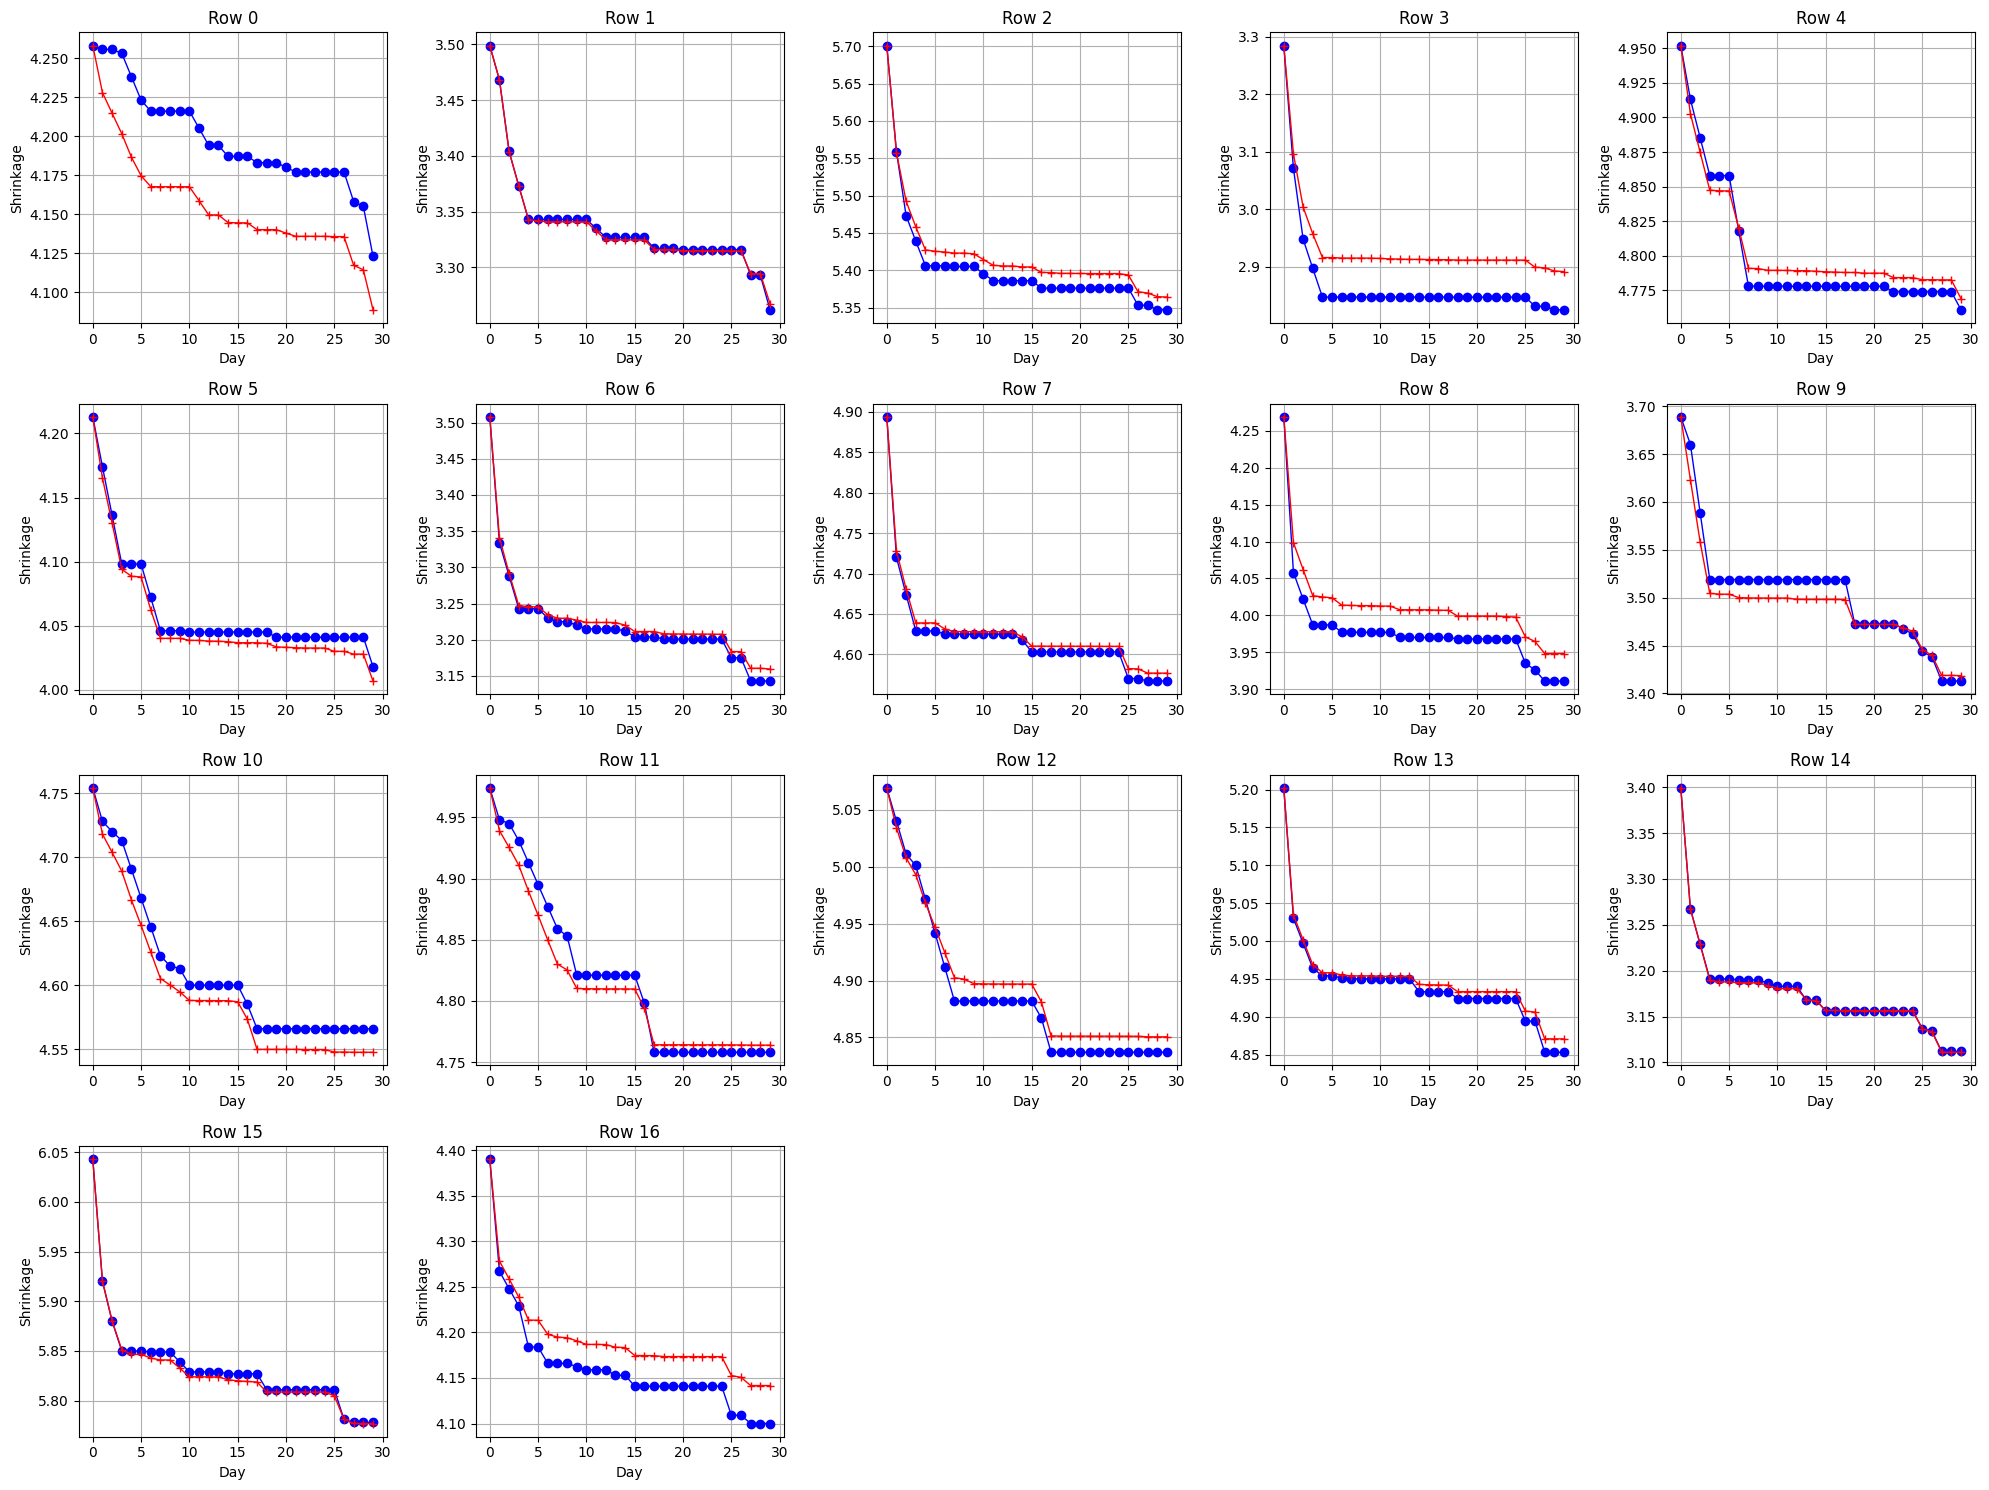

In [11]:
plt.figure(figsize=(20, 15))
for i in range(0,num_rows):
    plt.subplot(rows, cols, i + 1)
    plt.plot(y.iloc[i].values, marker='o', linewidth=1, color='blue', label='Actual')
    plt.plot(y_pred[i], marker='+', linewidth=1, color='red', label='Predicted')
    plt.title(f"Row {i}")
    plt.xlabel("Day")
    plt.ylabel("Shrinkage")
    plt.grid(True)
    
plt.tight_layout()
plt.savefig("./plots/xqboost-delta-model.png")
plt.show()

## MODEL - 3

In [12]:
delta_model_2 = ElasticNet(alpha=0.01, l1_ratio=0.7)
X = df.drop(columns=target_cols[1:] + ["Mix_name"])
y = df[target_cols]
delta_model_2.fit(X, y_delta)
delta_pred = np.maximum(delta_model_2.predict(X), 0)

In [13]:
y0 = y.values[:, [0]]  # day_01
y_rest = y0 - np.cumsum(delta_pred, axis=1)
y_pred = np.hstack([y0, y_rest])


In [14]:
mae = mean_absolute_error(y.values.flatten(),y_pred.flatten())
mse_raw = mean_squared_error(y.values.flatten(), y_pred.flatten())
r2_raw = r2_score(y.values.flatten(), y_pred.flatten())

print("MAE:", mae_raw)
print("MSE:",mse_raw)
print("R2:",r2_raw)

MAE: 0.008619678175683137
MSE: 0.0035778371025596213
R2: 0.9946148699709387


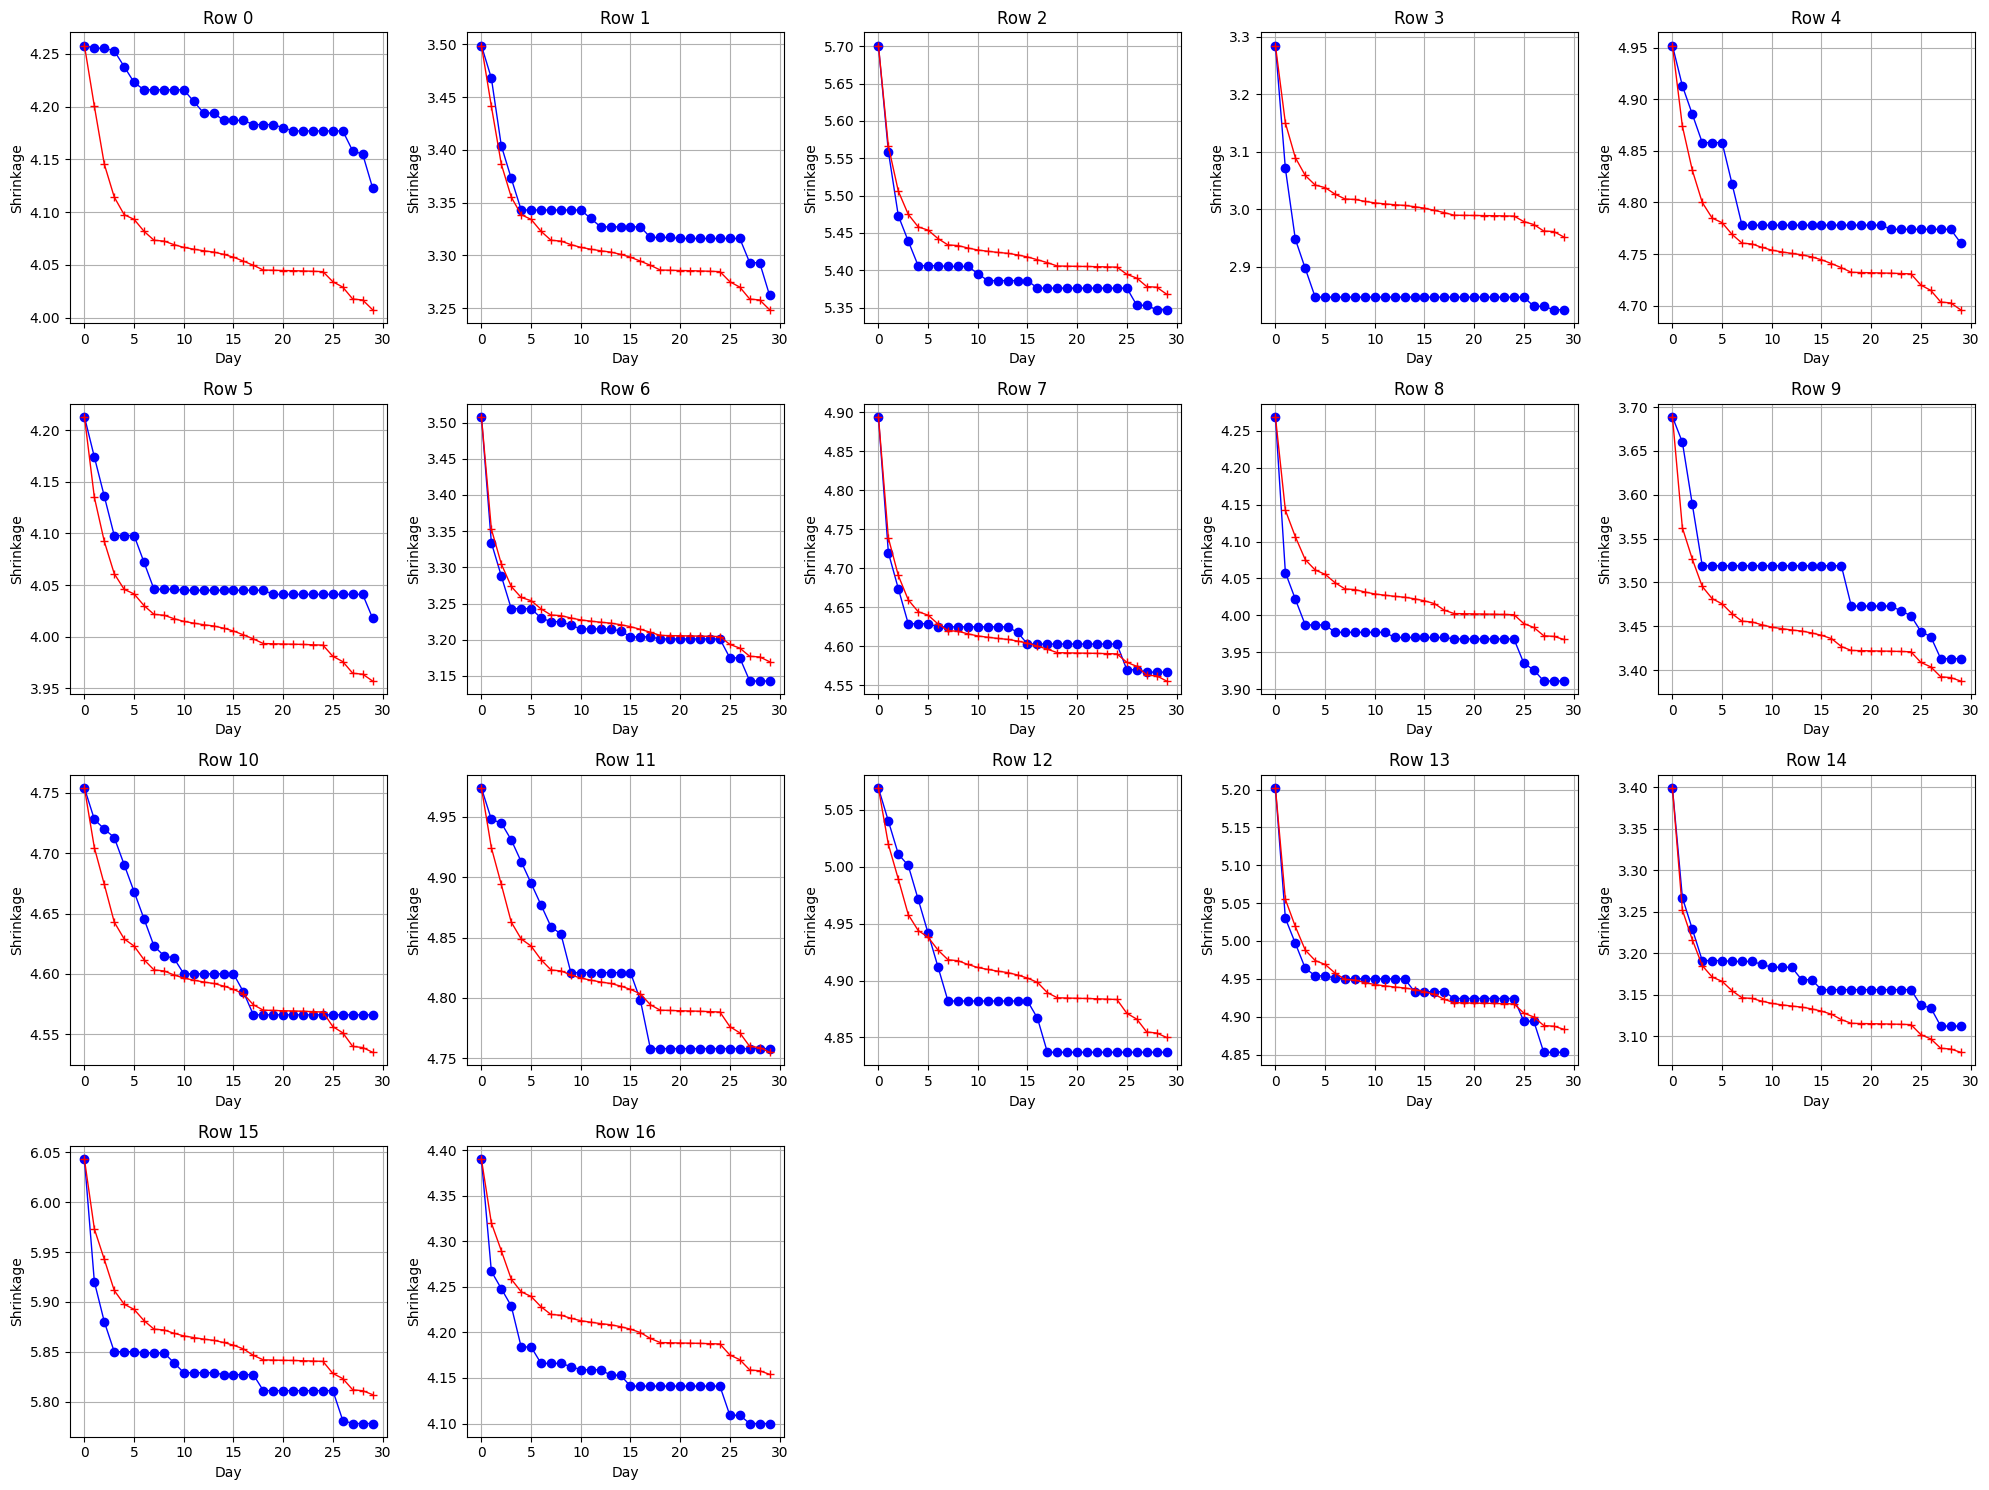

In [15]:
plt.figure(figsize=(20, 15))
for i in range(0,num_rows):
    plt.subplot(rows, cols, i + 1)
    plt.plot(y.iloc[i].values, marker='o', linewidth=1, color='blue', label='Actual')
    plt.plot(y_pred[i], marker='+', linewidth=1, color='red', label='Predicted')
    plt.title(f"Row {i}")
    plt.xlabel("Day")
    plt.ylabel("Shrinkage")
    plt.grid(True)
    
plt.tight_layout()
plt.savefig("./plots/elastic-model.png")
plt.show()

In [16]:
joblib.dump(model,"./models/xgboost-istonic-enforced-regression-model.pkl")
joblib.dump(delta_model,"./models/xgboost-delta-model.pkl")
joblib.dump(delta_model_2,"./models/elasticnet-delta-model.pkl")

['./models/elasticnet-delta-model.pkl']